# step01_dataset_validation — Dataset Overview and Validation

Establish scope, completeness, ordering, and article coverage before interpreting patterns.

Run cells from top to bottom. Shared helpers and file paths are in `analysis_common.py`. Outputs go to `analysis_results/` and `figures/`.

In [1]:
from pathlib import Path
import sys
from IPython.display import display
ROOT = Path.cwd().resolve()
while not (ROOT / 'analysis' / 'analysis_common.py').exists() and ROOT.parent != ROOT: ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'analysis'))
from analysis_common import *
df = load_revisions()
valid = df.dropna(subset=['timestamp'])
article_counts = df.groupby('article_title').size().sort_values(ascending=False)
summary = pd.DataFrame([{'revision_records': len(df), 'articles': df.article_title.nunique(), 'unique_nonempty_usernames': df.username.nunique(dropna=True), 'mean_revisions_per_article': article_counts.mean(), 'median_revisions_per_article': article_counts.median(), 'earliest_timestamp_utc': valid.timestamp.min(), 'latest_timestamp_utc': valid.timestamp.max(), 'coverage_days': (valid.timestamp.max()-valid.timestamp.min()).total_seconds()/86400, 'invalid_timestamp_rows': df.timestamp.isna().sum()}])
display(summary.T.rename(columns={0:'value'}))
save_table(summary, 'step01_dataset_summary.csv')


,value
revision_records,313269
articles,31
unique_nonempty_usernames,88233
mean_revisions_per_article,10105.451613
median_revisions_per_article,9034.0
earliest_timestamp_utc,2001-05-14 08:28:10+00:00
latest_timestamp_utc,2026-11-10 06:27:03+00:00
coverage_days,9310.915891
invalid_timestamp_rows,0


WindowsPath('C:/Users/Jackson/Desktop/class/arch/finalProject/analysis/analysis_results/step01_dataset_summary.csv')

In [2]:
fields = ['timestamp','revision_id','username','edit_comment','article_size_bytes']
missing_masks={'timestamp':df.timestamp.isna(),'revision_id':df.revision_id.isna(),'username':df.username_missing,'edit_comment':df.comment_missing,'article_size_bytes':df.article_size_bytes.isna()}
missing = pd.DataFrame({'field': fields, 'missing_count': [int(missing_masks[c].sum()) for c in fields]})
missing['missing_percent'] = 100 * missing.missing_count / len(df)
missing['nonempty_percent'] = 100 - missing.missing_percent
article_missing = pd.concat([df[['article_title']],pd.DataFrame({c:missing_masks[c] for c in fields})],axis=1).groupby('article_title').mean().mul(100).add_suffix('_missing_pct').reset_index()
quality = pd.DataFrame([{'duplicate_revision_ids': int(df.revision_id.duplicated(keep=False).sum()), 'duplicate_rows_after_first': int(df.revision_id.duplicated().sum()), 'unparseable_timestamps': int(df.timestamp.isna().sum()), 'negative_sizes': int((df.article_size_bytes < 0).sum()), 'missing_size_values': int(df.article_size_bytes.isna().sum()), 'missing_revision_ids': int(df.revision_id.isna().sum()), 'missing_parent_ids': int(df.parent_id.isna().sum()), 'rows_out_of_chronological_order_within_article': int((df.groupby('article_title', sort=False).timestamp.apply(lambda s: s.dropna().diff().lt(pd.Timedelta(0)).sum())).sum()), 'timestamp_duplicates': int(df.duplicated(['article_title','timestamp','revision_id']).sum())}])
display(missing); display(quality.T); display(article_missing.sort_values('timestamp_missing_pct', ascending=False).head(10))
save_table(missing, 'step01_field_completeness.csv'); save_table(article_missing, 'step01_article_completeness.csv'); save_table(quality, 'step01_validation_report.csv')

,field,missing_count,missing_percent,nonempty_percent
0,timestamp,0,0.000000,100.000000
1,revision_id,0,0.000000,100.000000
2,username,0,0.000000,100.000000
3,edit_comment,59128,18.874514,81.125486
4,article_size_bytes,0,0.000000,100.000000


,0
duplicate_revision_ids,0
duplicate_rows_after_first,0
unparseable_timestamps,0
negative_sizes,0
missing_size_values,0
missing_revision_ids,0
missing_parent_ids,0
rows_out_of_chronological_order_within_article,0
timestamp_duplicates,0


,article_title,timestamp_missing_pct,revision_id_missing_pct,username_missing_pct,edit_comment_missing_pct,article_size_bytes_missing_pct
0,American Civil War,0.0,0.0,0.0,13.951775,0.0
1,American Revolution,0.0,0.0,0.0,15.462767,0.0
2,Arab Spring,0.0,0.0,0.0,18.069379,0.0
3,Assassination of John F. Kennedy,0.0,0.0,0.0,17.184824,0.0
4,Atomic bombings of Hiroshima and Nagasaki,0.0,0.0,0.0,11.834814,0.0
5,Battle of Gettysburg,0.0,0.0,0.0,23.732796,0.0
6,Black Death,0.0,0.0,0.0,19.705046,0.0
7,Boston Tea Party,0.0,0.0,0.0,21.959923,0.0
8,Chinese Revolution,0.0,0.0,0.0,41.666667,0.0
9,Cold War,0.0,0.0,0.0,19.734963,0.0


WindowsPath('C:/Users/Jackson/Desktop/class/arch/finalProject/analysis/analysis_results/step01_validation_report.csv')

,article_title,revisions,share_of_records_pct,cumulative_share_pct
0,World War II,28609,9.132407,9.132407
1,September 11 attacks,22585,7.209459,16.341866
2,World War I,20277,6.472712,22.814578
3,Vietnam War,19378,6.185738,29.000316
4,Assassination of John F. Kennedy,15182,4.846314,33.846630
5,American Civil War,14930,4.765872,38.612502
6,Korean War,14749,4.708094,43.320597
7,Gulf War,14132,4.511139,47.831736
8,Cold War,12602,4.022741,51.854477
9,Great Depression,11555,3.688523,55.543000


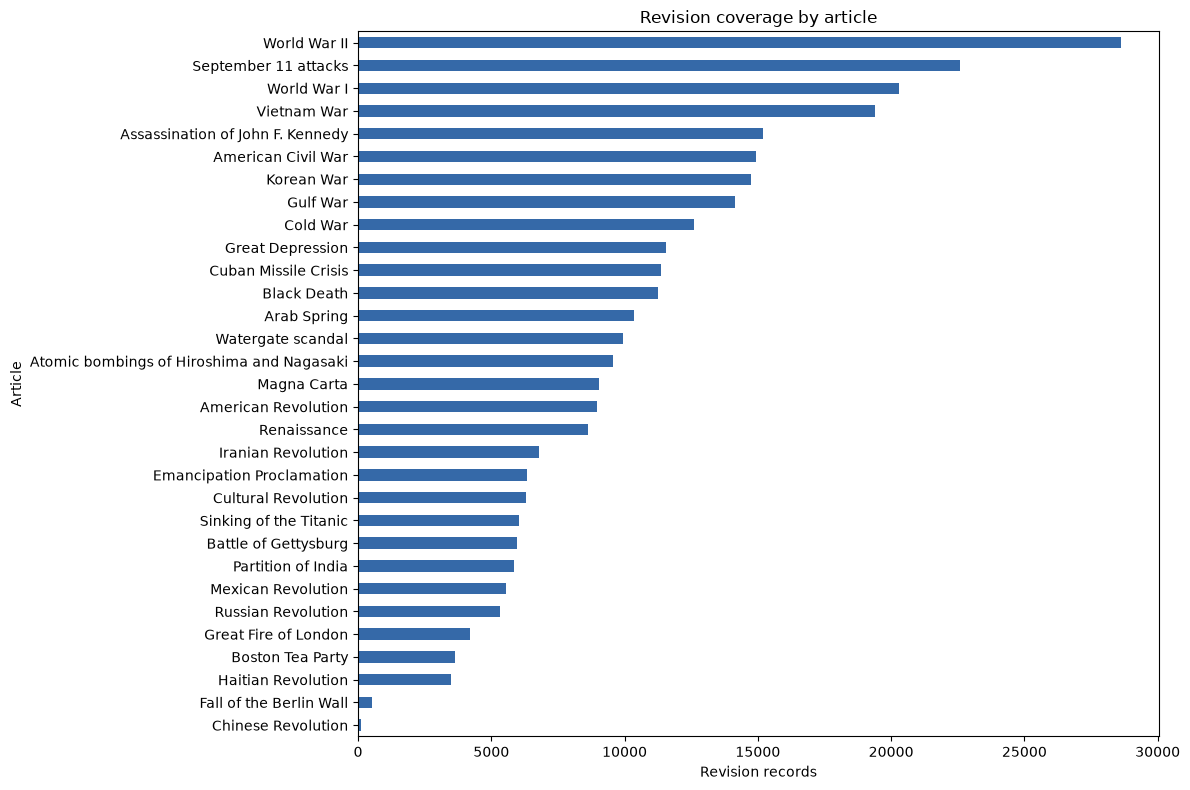

In [3]:
coverage = article_counts.rename('revisions').reset_index()
coverage['share_of_records_pct'] = 100*coverage.revisions/len(df)
coverage['cumulative_share_pct'] = coverage.share_of_records_pct.cumsum()
coverage.to_csv(OUTPUT_DIR/'step01_article_coverage.csv', index=False)
display(coverage)
fig, ax = plt.subplots(figsize=(12,8)); coverage.sort_values('revisions').plot.barh(x='article_title',y='revisions',ax=ax,legend=False,color='#3569a8'); ax.set(title='Revision coverage by article',xlabel='Revision records',ylabel='Article'); finish_plot(fig,'step01_article_coverage.png')


In [4]:
# Parent-link integrity and unusually large size values need separate review.
revision_lookup = df.dropna(subset=['revision_id']).drop_duplicates('revision_id').set_index('revision_id')
parents = df.dropna(subset=['parent_id']).copy()
parents['parent_in_collection'] = parents.parent_id.isin(revision_lookup.index)
parents['parent_same_article'] = parents.parent_id.map(revision_lookup.article_title).eq(parents.article_title)
parents['parent_timestamp'] = parents.parent_id.map(revision_lookup.timestamp)
parents['parent_not_earlier'] = parents.parent_timestamp.notna() & (parents.parent_timestamp >= parents.timestamp)
parent_integrity = pd.DataFrame([{'records_with_parent_id': len(parents), 'parent_not_in_collected_dataset': int((~parents.parent_in_collection).sum()), 'parent_belongs_to_another_article': int((~parents.parent_same_article & parents.parent_in_collection).sum()), 'parent_timestamp_not_earlier_than_child': int(parents.parent_not_earlier.sum())}])
extreme_sizes = df.nlargest(25, 'article_size_bytes')[['article_title','timestamp','revision_id','parent_id','article_size_bytes','edit_comment']]
parent_anomalies = parents[(~parents.parent_in_collection) | parents.parent_not_earlier][['article_title','timestamp','revision_id','parent_id','parent_timestamp','parent_in_collection','parent_not_earlier','edit_comment']]
save_table(parent_integrity, 'step01_parent_link_validation.csv'); save_table(parent_anomalies, 'step01_parent_link_anomalies.csv'); save_table(extreme_sizes, 'step01_largest_observed_sizes.csv')
display(parent_integrity); display(parent_anomalies.head(20)); display(extreme_sizes.head(10))


,records_with_parent_id,parent_not_in_collected_dataset,parent_belongs_to_another_article,parent_timestamp_not_earlier_than_child
0,313269,23,0,84


,article_title,timestamp,revision_id,parent_id,parent_timestamp,parent_in_collection,parent_not_earlier,edit_comment
0,American Civil War,2001-11-02 23:28:55+00:00,334930481,334189771,2009-12-27 02:28:18+00:00,True,True,*Added mention of battles in the Western theat...
45,American Civil War,2003-02-06 16:15:44+00:00,646923,646914,2003-02-06 16:15:44+00:00,True,True,paragraph structure
46,American Civil War,2003-02-06 16:15:44+00:00,646935,646923,2003-02-06 16:15:44+00:00,True,True,paragraph structure
3267,American Civil War,2006-04-26 18:20:17+00:00,50291434,50291431,2006-04-26 18:20:17+00:00,True,True,
3830,American Civil War,2006-06-07 14:31:22+00:00,57358520,57358519,2006-06-07 14:31:22+00:00,True,True,Reverted edits by [[Special:Contributions/63.1...
14930,American Revolution,2001-09-22 23:57:02+00:00,380413836,379881811,2010-08-20 01:17:45+00:00,True,True,*i've already linked to [[American Revolution]...
16542,American Revolution,2006-05-16 15:54:29+00:00,53522787,53522784,2006-05-16 15:54:29+00:00,True,True,Reverted edits by [[Special:Contributions/206....
18083,American Revolution,2007-03-08 03:46:51+00:00,113492926,113492925,2007-03-08 03:46:51+00:00,True,True,/* Origins */
20866,American Revolution,2013-02-19 21:22:04+00:00,539111047,539111044,2013-02-19 21:22:04+00:00,True,True,Configured pending changes settings for [[Amer...
23887,Arab Spring,2011-01-27 16:55:08+00:00,410393753,0,NaT,False,False,[[WP:AES|←]]Created page with 'The '''2010–201...


,article_title,timestamp,revision_id,parent_id,article_size_bytes,edit_comment
201571,Russian Revolution,2005-10-25 19:19:49+00:00,26464358,26464193,3559867,
267007,World War I,2005-12-08 13:02:16+00:00,30587516,30567121,2716074,/* Causes */
267009,World War I,2005-12-08 13:03:19+00:00,30587586,30587560,2716074,/* Causes */
201570,Russian Revolution,2005-10-25 19:17:54+00:00,26464193,26464160,2480051,
201569,Russian Revolution,2005-10-25 19:17:30+00:00,26464160,26464058,2479931,
38229,Assassination of John F. Kennedy,2007-02-19 20:54:11+00:00,109382763,109381785,1793519,/* Autopsy */
38230,Assassination of John F. Kennedy,2007-02-19 21:01:29+00:00,109384443,109382763,1763881,removed vandalism
290446,World War II,2005-12-23 03:19:58+00:00,32441095,32440959,1613424,/* Participants */
201568,Russian Revolution,2005-10-25 19:16:13+00:00,26464058,26463869,1400115,
265032,World War I,2004-09-20 15:53:58+00:00,6017113,6015422,847143,
